### 1. Import

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

### 2. Load Paths

In [2]:
PROJECT_ROOT = Path(r"C:\Projects\BrainTumorAI")
MODEL_PATH = PROJECT_ROOT / "models" / "segmentation" / "unet_augmented_best.keras"


### 3. Create the inference pipeline

#### Set up paths and prediction threshold

In [3]:
# Use the threshold selected during your evaluation.
THRESHOLD = 0.40
IMG_SIZE = (256, 256)

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("Model ready for inference.")

Model ready for inference.


#### Load one MRI image and predict its tumor mask

In [4]:
# Replace this with an actual MRI image path
IMAGE_PATH = PROJECT_ROOT / "data" / "segmentation_task" / "test" / "images" / "brisc2025_test_00001_gl_ax_t1.jpg"

if not IMAGE_PATH.exists():
    raise FileNotFoundError(
        f"Image not found: {IMAGE_PATH}\n"
        "Update IMAGE_PATH to an existing MRI image."
    )

# Load the original grayscale MRI
original_image = Image.open(IMAGE_PATH).convert("L")
original_array = np.array(original_image)

original_height, original_width = original_array.shape

# Match the model's training preprocessing
image_tensor = tf.convert_to_tensor(original_array[..., np.newaxis])
image_tensor = tf.image.resize_with_pad(
    image_tensor,
    IMG_SIZE[0],
    IMG_SIZE[1],
    method="bilinear"
)

image_tensor = tf.cast(image_tensor, tf.float32) / 255.0
image_tensor = tf.expand_dims(image_tensor, axis=0)

# Predict the tumor probability map
prediction = model.predict(image_tensor, verbose=0)[0, :, :, 0]

# Convert probabilities into a binary mask
predicted_mask = (prediction >= THRESHOLD).astype(np.uint8)

print("MRI dimensions:", original_array.shape)
print("Prediction dimensions:", prediction.shape)
print("Predicted tumor pixels:", int(predicted_mask.sum()))
print("Prediction probability range:",
      float(prediction.min()), "to", float(prediction.max()))

MRI dimensions: (512, 512)
Prediction dimensions: (256, 256)
Predicted tumor pixels: 1582
Prediction probability range: 5.198139696460657e-10 to 0.999964714050293


#### Visualize the prediction

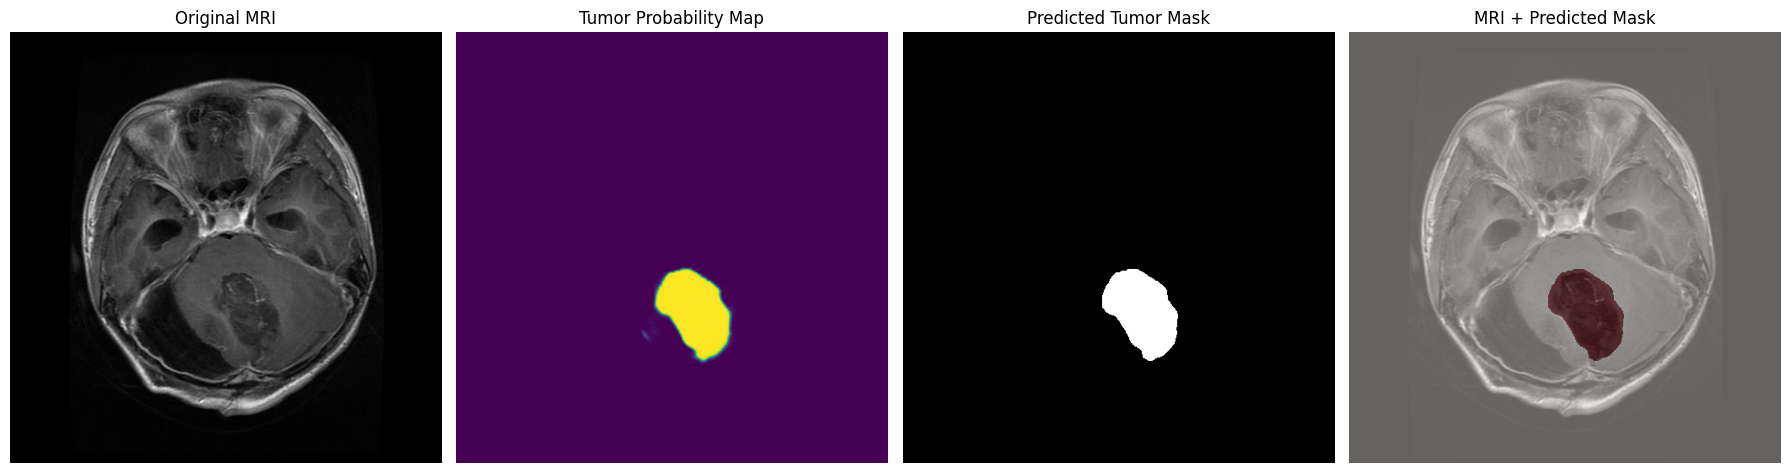

In [5]:
# Calculate the resized image dimensions used by resize_with_pad
scale = min(
    IMG_SIZE[0] / original_height,
    IMG_SIZE[1] / original_width
)

resized_height = min(IMG_SIZE[0], max(1, round(original_height * scale)))
resized_width = min(IMG_SIZE[1], max(1, round(original_width * scale)))

pad_top = (IMG_SIZE[0] - resized_height) // 2
pad_left = (IMG_SIZE[1] - resized_width) // 2

# Remove padding from the prediction
cropped_prediction = prediction[
    pad_top:pad_top + resized_height,
    pad_left:pad_left + resized_width
]

# Resize probability map to original image dimensions
original_size_prediction = tf.image.resize(
    cropped_prediction[..., np.newaxis],
    [original_height, original_width],
    method="bilinear"
).numpy()[..., 0]

# Threshold after resizing for the final overlay
original_size_mask = (
    original_size_prediction >= THRESHOLD
)

# Plot MRI, probability map, binary mask, and overlay
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(original_array, cmap="gray")
axes[0].set_title("Original MRI")

axes[1].imshow(original_size_prediction, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Tumor Probability Map")

axes[2].imshow(original_size_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Predicted Tumor Mask")

axes[3].imshow(original_array, cmap="gray")
axes[3].imshow(
    original_size_mask,
    cmap="Reds",
    alpha=0.4,
    vmin=0,
    vmax=1
)
axes[3].set_title("MRI + Predicted Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()